In [9]:
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
url = "amz_uk_price_prediction_dataset.csv"

df = pd.read_csv(url)

In [3]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [11]:
df_product = df.category.value_counts()

In [12]:
#create a Table of frecuencies of category products

df_product

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [13]:
#which are the top 5

df_product.head()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

C:\Users\ivanj\AppData\Local\Temp\ipykernel_12856\1005505425.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=df_product.head().index, x=df_product.head().values, palette="Set3");


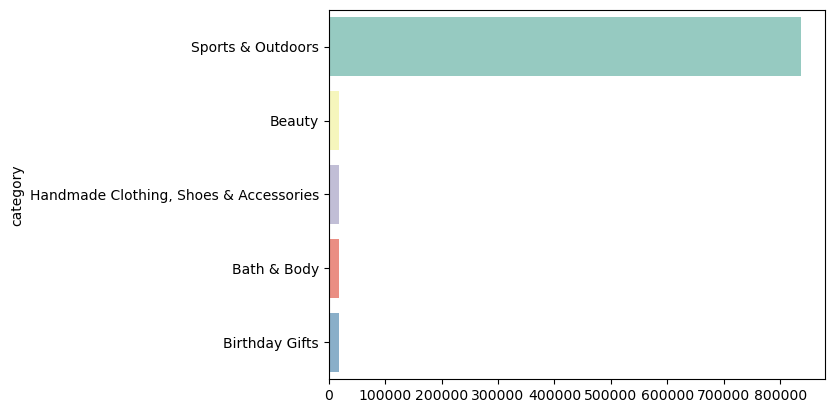

In [18]:
#Use of a bar chart

sns.barplot(y=df_product.head().index, x=df_product.head().values, palette="Set3");

<Axes: ylabel='count'>

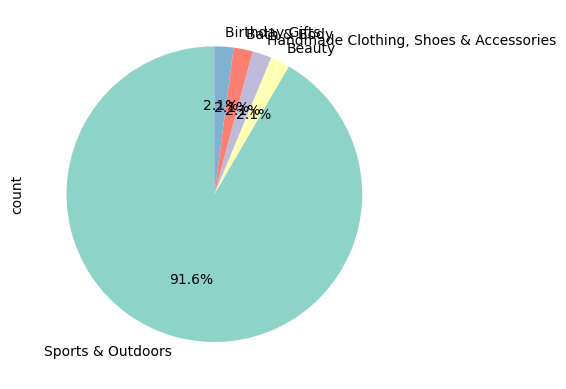

In [22]:
#Use a piechart

#the pie is dominated by the sports & outdoors category

df_product.head().plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

In [25]:
# exercise 2 Calculate the mean, median, and mode for the price of products.

price_mean = df["price"].mean()
price_median = df["price"].median()
price_mode = df["price"].mode()
print(price_mean)
print(price_median)
print(price_mode)

89.24380943923663
19.09
0    9.99
Name: price, dtype: float64


In [26]:
#What's the average price point of products listed? How does this compare with the most common price point (mode)?
print(price_mean)
print(price_mode)

#The average price is almost 90 and the most repeated is almost 10 this could be because there is some ouliers that modify the mean price a lot or that the price are so different that there few coincidences
#and casually the low price of the mode is because some product have that price

89.24380943923663
0    9.99
Name: price, dtype: float64


In [28]:
#Determine the variance, standard deviation, range, and interquartile range for product price.

price_var = df["price"].var()
price_std = df["price"].std()
price_range = (df["price"].max() - df["price"].min())
quantiles_price = df['price'].quantile([0.25, 0.5, 0.75])
price_var, price_std, price_range, quantiles_price

(119445.48532256528,
 345.60886175352226,
 100000.0,
 0.25     9.99
 0.50    19.09
 0.75    45.99
 Name: price, dtype: float64)

In [29]:
#How varied are the product prices? Are there any indicators of a significant spread in prices?

#The range variable indicate us the different in price between the cheapest product and the most expensive product

In [36]:
df["price"]

0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2443651, dtype: float64

<Axes: xlabel='price', ylabel='Count'>

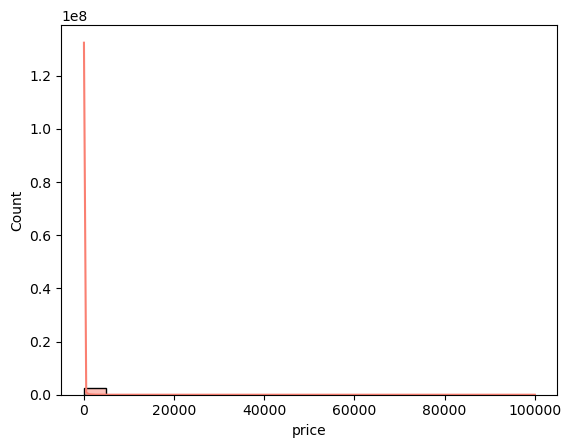

In [34]:
#Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices.

sns.histplot(df['price'], kde=True, bins=20, color="salmon")

#the Histplot is difficult to read due to the outliers in price that are so high that makes difficult to read the rest of the data. 1 possible solution could be drop this value

<Axes: ylabel='price'>

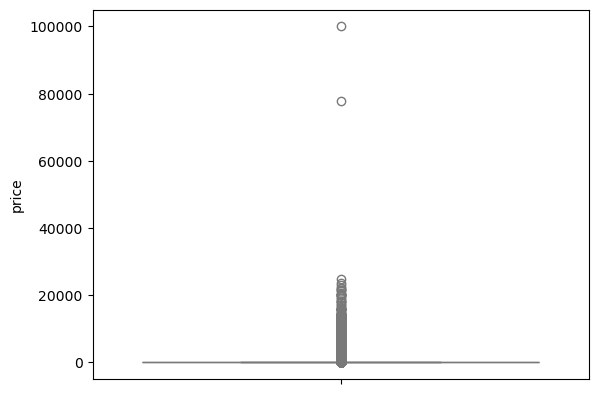

In [37]:
#Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

sns.boxplot(data = df['price'], color="lightblue")

#there outliers of about 100.000 and 80.000 that makes the result so difficult to read

In [38]:
#Calculate the mean, median, and mode for the rating of products.

stars_mean = df["stars"].mean()
stars_median = df["stars"].median()
stars_mode = df["stars"].mode()
stars_mean, stars_median, stars_mode

(2.152836472966065,
 0.0,
 0    0.0
 Name: stars, dtype: float64)

In [39]:
#How do customers generally rate products? Is there a common trend?

#The most common trend is to rate the product with a 0 in most of the cases

In [40]:
#Determine the variance, standard deviation, and interquartile range for product rating.

stars_var = df["stars"].var()
stars_std = df["stars"].std()
stars_range = (df["stars"].max() - df["stars"].min())
quantiles_stars = df['stars'].quantile([0.25, 0.5, 0.75])
stars_var, stars_std, stars_range, quantiles_stars

(4.81743402976196,
 2.1948653785054697,
 5.0,
 0.25    0.0
 0.50    0.0
 0.75    4.4
 Name: stars, dtype: float64)

In [41]:
#Are the ratings consistent, or is there a wide variation in customer feedback?

#there is a enormous variation and we can see that in the quantiles because more than 50% of the rating are 0 but a 25% of the rating are above the 4.4 in rating

In [43]:
#Calculate the skewness and kurtosis for the rating column.

skewness_stars = df['stars'].skew()
kurtosis_stars = df['stars'].kurtosis()

skewness_stars, kurtosis_stars

(0.08120735761080985, -1.9260061280432985)

In [46]:
#Are the ratings normally distributed, or do they lean towards higher or lower values?

#The values are well distributed in right and left skewed but the kurtosis tell us that the peak is not pronunciated and the tails are heavy 

<Axes: xlabel='stars', ylabel='Count'>

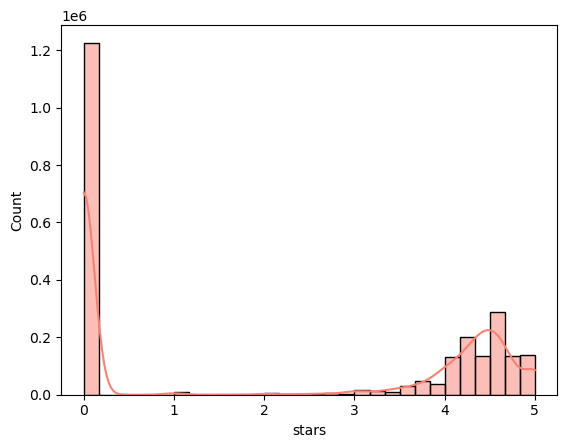

In [47]:
#Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

sns.histplot(df['stars'], kde=True, bins=30, color="salmon")